1) Crear datos_prep.py

In [ ]:
%%writefile datos_prep.py
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from google.colab import files

def cargar_y_preprocesar_datos(target_col="customer_status", max_unique_categories=50, test_size=0.2, random_state=42):
    print("Por favor, selecciona el dataset a procesar:")
    uploaded = files.upload()

    file_name = list(uploaded.keys())[0]
    df = pd.read_csv(file_name)
    print(f"\nDataset '{file_name}' cargado exitosamente.")

    # 1. Definir target y separar X / y
    if target_col in df.columns:
        X = df.drop(columns=[target_col])
        y = df[target_col]
    else:
        X = df.iloc[:, :-1]
        y = df.iloc[:, -1]

    # 2. Filtro de limpieza inteligente (alta cardinalidad)
    cols_a_eliminar = [col for col in X.select_dtypes(include=['object']).columns
                       if X[col].nunique() > max_unique_categories]

    if cols_a_eliminar:
        print(f"\nEliminando {len(cols_a_eliminar)} columnas con alta cardinalidad: {cols_a_eliminar}")
        X = X.drop(columns=cols_a_eliminar)

    # 3. Transformación de categóricas e imputación de nulos
    X = pd.get_dummies(X, drop_first=True)
    X = X.fillna(X.mean(numeric_only=True))

    # 4. Escalado de datos
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    X = pd.DataFrame(X_scaled, columns=X.columns)

    # Guardar y descargar en Colab
    df_limpio_exportar = X.copy()
    df_limpio_exportar[target_col] = y.values

    nombre_archivo_salida = "car_insurance_claim_datos_limpios.csv"
    df_limpio_exportar.to_csv(nombre_archivo_salida, index=False)
    print(f"\n[INFO] Archivo guardado. Descargando automáticamente...")
    files.download(nombre_archivo_salida)

    # 5. División en Train / Test
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    print("\n¡Datos preprocesados y divididos exitosamente!")
    return X, y, X_train, X_test, y_train, y_test, df

Writing datos_prep.py


2) Crear train.py

In [ ]:
%%writefile train.py
import mlflow
import mlflow.sklearn
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

def entrenar_y_registrar_modelos(X, y, X_train, y_train):

    """
    Configura el experimento en MLflow, entrena Logistic Regression y Random Forest
    usando validación cruzada (K-Fold) y registra parámetros, métricas y artefactos.
    """
    # Configurar el experimento en MLflow
    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    mlflow.set_experiment("Pipeline_Clientes_MLflow")

    # ==========================================
    # 1. MODELO 1: LOGISTIC REGRESSION (con K-Fold CV)
    # ==========================================
    model_name_lr = "Logistic_Regression"

    with mlflow.start_run(run_name=model_name_lr):
        C_param = 1.0
        max_iter_param = 1000

        # Registrar parámetros
        mlflow.log_param("model_type", "LogisticRegression")
        mlflow.log_param("C", C_param)
        mlflow.log_param("max_iter", max_iter_param)
        mlflow.log_param("cv_folds", 3)

        # Definir modelo
        clf = LogisticRegression(C=C_param, max_iter=max_iter_param, random_state=42)

        # Ejecutar Validación Cruzada (K-Fold, cv=3)
        cv_scores = cross_val_score(clf, X, y, cv=3, scoring='accuracy')
        mean_accuracy = cv_scores.mean()

        # Entrenar en el conjunto completo para guardar el artefacto
        clf.fit(X_train, y_train)

        # Registrar métricas de validación cruzada en MLflow
        mlflow.log_metric("cv_accuracy_mean", mean_accuracy)
        mlflow.log_metric("cv_accuracy_std", cv_scores.std())

        # Guardar artefacto
        mlflow.sklearn.log_model(clf, artifact_path="model")
        print(f"Logistic Regression - K-Fold Accuracy Promedio: {mean_accuracy:.4f}")

    # ==========================================
    # 2. MODELO 2: RANDOM FOREST (con K-Fold CV)
    # ==========================================
    model_name_rf = "Random_Forest"

    with mlflow.start_run(run_name=model_name_rf):
        n_estimators_param = 100
        max_depth_param = 10

        # Registrar parámetros
        mlflow.log_param("model_type", "RandomForestClassifier")
        mlflow.log_param("n_estimators", n_estimators_param)
        mlflow.log_param("max_depth", max_depth_param)
        mlflow.log_param("cv_folds", 3)

        # Definir modelo
        rf_clf = RandomForestClassifier(
            n_estimators=n_estimators_param,
            max_depth=max_depth_param,
            random_state=42
        )

        # Ejecutar Validación Cruzada (K-Fold, cv=3)
        cv_scores_rf = cross_val_score(rf_clf, X, y, cv=3, scoring='accuracy')
        mean_accuracy_rf = cv_scores_rf.mean()

        # Entrenar en el conjunto completo para guardar el artefacto
        rf_clf.fit(X_train, y_train)

        # Registrar métricas de validación cruzada en MLflow
        mlflow.log_metric("cv_accuracy_mean", mean_accuracy_rf)
        mlflow.log_metric("cv_accuracy_std", cv_scores_rf.std())

        # Guardar artefacto
        mlflow.sklearn.log_model(
            rf_clf,
            artifact_path="model",
            serialization_format="cloudpickle"
        )
        print(f"Random Forest - K-Fold Accuracy Promedio: {mean_accuracy_rf:.4f}")

    print("\nModelos evaluados con K-Fold Cross-Validation y registrados en MLflow exitosamente")

    # Cálculo de métricas

    from sklearn.model_selection import cross_val_predict
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

    print("\n--- REPORTE DE MÉTRICAS ADICIONALES DE CLASIFICACIÓN ---")

    for nombre, modelo_inst in [("Logistic_Regression", clf), ("Random_Forest", rf_clf)]:
        # Predicciones por validación cruzada para métricas imparciales
        y_pred_cv = cross_val_predict(modelo_inst, X, y, cv=3)

        acc = accuracy_score(y, y_pred_cv)
        prec = precision_score(y, y_pred_cv, average='weighted', zero_division=0)
        rec = recall_score(y, y_pred_cv, average='weighted', zero_division=0)
        f1 = f1_score(y, y_pred_cv, average='weighted', zero_division=0)

        try:
            y_prob_cv = cross_val_predict(modelo_inst, X, y, cv=3, method="predict_proba")[:, 1]
            roc_auc = roc_auc_score(y, y_prob_cv)
        except Exception:
            roc_auc = 0.0

        print(f"\nModelo: {nombre}")
        print(f"  • Accuracy:  {acc:.4f}")
        print(f"  • Precision: {prec:.4f}")
        print(f"  • Recall:    {rec:.4f}")
        print(f"  • F1-Score:  {f1:.4f}")
        print(f"  • ROC-AUC:   {roc_auc:.4f}")

Writing train.py


3) Creamos entrena.ipynb

a) Instalación

In [ ]:
!pip install mlflow scikit-learn pandas numpy
import mlflow
import mlflow.sklearn
print("Librerías listas.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 44.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 59.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.

b) Carga y Preprocesamiento llamando a datos_prep.py

In [ ]:
from datos_prep import cargar_y_preprocesar_datos

# Esto abrirá el botón 'Choose Files' para subir tu CSV
X, y, X_train, X_test, y_train, y_test, df = cargar_y_preprocesar_datos()

Por favor, selecciona el dataset a procesar:


Saving car_insurance_claim.csv to car_insurance_claim.csv

Dataset 'car_insurance_claim.csv' cargado exitosamente.

Eliminando 8 columnas con alta cardinalidad: ['record_id', 'full_name', 'email', 'phone', 'date_of_birth', 'signup_date', 'last_login', 'postal_code']

[INFO] Archivo guardado. Descargando automáticamente...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


¡Datos preprocesados y divididos exitosamente!


c) Inspeccion del DataSet

In [ ]:
print("Columnas disponibles en el dataset:")
print(df.columns.tolist())

print("\nPrimeras filas del dataset:")
display(df.head())

Columnas disponibles en el dataset:
['record_id', 'full_name', 'email', 'email_valid', 'phone', 'date_of_birth', 'signup_date', 'last_login', 'country', 'state_province', 'city', 'postal_code', 'customer_status', 'plan', 'preferred_language', 'timezone', 'height_cm', 'weight_kg', 'marketing_consent', 'amount_spent_mxn']

Primeras filas del dataset:


,record_id,full_name,email,email_valid,phone,date_of_birth,signup_date,last_login,country,state_province,city,postal_code,customer_status,plan,preferred_language,timezone,height_cm,weight_kg,marketing_consent,amount_spent_mxn
0,8U9C09,Adriana Castillo,adriana.castillo@empresa.com,True,NaN,1993-12-09,2022-02-08 08:42:00,2025-09-15 08:42:00,Argentina,NaN,Córdoba,09742,Inactivo,Pro,en,EST,178.9,90.7,N,265.51
1,1302,Adriana Castillo,adriana.castillo@outlook.com,True,+1-148-356-5086,1967-03-27,2023-06-18 08:42:00,2025-07-25 08:42:53,Argentina,NaN,Rosario,54110,Prueba,Empresarial,en,UTC-3,158.5,99.2,No,419.49
2,131,Adriana Chávez,adriana.chávez@empresa.com,False,(005) 577-8487,2003-05-20,2022-09-19 00:00:00,2024-12-24 00:00:00,Estados Unidos,NaN,Los Angeles,68845-3174,Prueba,Básico,es,UTC-5,159.0,82.4,YES,169.94
3,QVTMGD,Adriana Chávez,adriana.chávez@hotmail.com,False,+52 39 2186 0432,1984-09-07,2025-01-29 00:00:00,2025-04-15 08:42:00,España,NaN,Bilbao,54351,Prueba,Básico,es,EST,176.2,50.7,NO,196.63
4,5332,Adriana Chávez,adriana.chávez@yahoo.com,False,+52 70 7393 1492,1966-03-15,2024-12-01 00:00:00,2025-03-22 00:00:00,Brasil,NaN,Brasília,NaN,Prueba,Empresarial,en,UTC-3,164.3,70.6,0,617.60


d) Entrenamiento

In [ ]:
from train import entrenar_y_registrar_modelos

# Ejecuta el entrenamiento de ambos modelos con MLflow
entrenar_y_registrar_modelos(X, y, X_train, y_train)

2026/10/19 02:31:55 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/19 02:31:55 INFO mlflow.store.db.utils: Updating database tables
2026/10/19 02:31:58 INFO mlflow.tracking.fluent: Experiment with name 'Pipeline_Clientes_MLflow' does not exist. Creating a new experiment.
2026/10/19 02:31:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logistic Regression - K-Fold Accuracy Promedio: 0.3757


2026/10/19 02:32:08 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/19 02:32:08 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest - K-Fold Accuracy Promedio: 0.3748

Modelos evaluados con K-Fold Cross-Validation y registrados en MLflow exitosamente

--- REPORTE DE MÉTRICAS ADICIONALES DE CLASIFICACIÓN ---

Modelo: Logistic_Regression
  • Accuracy:  0.3757
  • Precision: 0.3489
  • Recall:    0.3757
  • F1-Score:  0.3418
  • ROC-AUC:   0.0000

Modelo: Random_Forest
  • Accuracy:  0.3748
  • Precision: 0.3802
  • Recall:    0.3748
  • F1-Score:  0.3253
  • ROC-AUC:   0.0000


e) Resultado y comparación

In [ ]:
experiment_name = "Pipeline_Clientes_MLflow"
experiment = mlflow.get_experiment_by_name(experiment_name)

if experiment:
    runs_df = mlflow.search_runs(experiment_ids=[experiment.experiment_id])
    cols = ['tags.mlflow.runName', 'params.model_type', 'metrics.cv_accuracy_mean']
    cols_existentes = [c for c in cols if c in runs_df.columns]

    df_resultados = runs_df[cols_existentes].sort_values(by='metrics.cv_accuracy_mean', ascending=False)
    print("Tabla Comparativa de Resultados en MLflow")
    display(df_resultados)
else:
    print("No se encontró el experimento especificado.")

Tabla Comparativa de Resultados en MLflow


,tags.mlflow.runName,params.model_type,metrics.cv_accuracy_mean
1,Logistic_Regression,LogisticRegression,0.375683
0,Random_Forest,RandomForestClassifier,0.374776


f) Gráfica

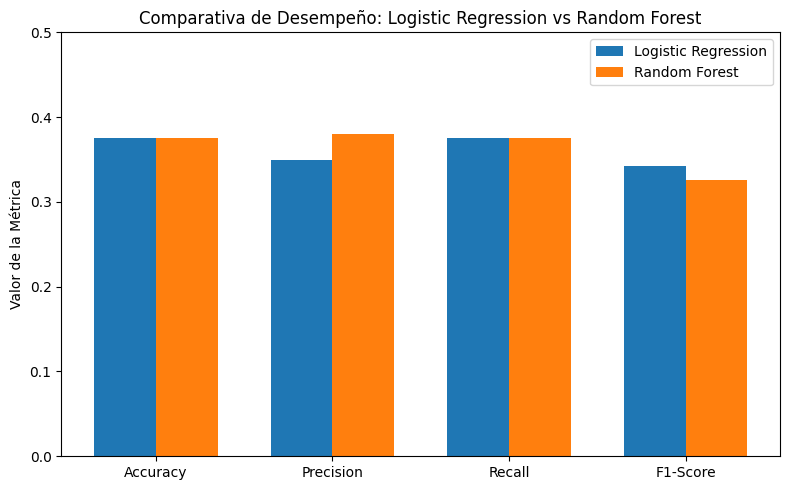

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Datos
metricas = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
log_reg = [0.3757, 0.3489, 0.3757, 0.3418]
rand_forest = [0.3748, 0.3802, 0.3748, 0.3253]

x = np.arange(len(metricas))
width = 0.35

# Crear la gráfica
fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, log_reg, width, label='Logistic Regression')
rects2 = ax.bar(x + width/2, rand_forest, width, label='Random Forest')

# Personalización
ax.set_ylabel('Valor de la Métrica')
ax.set_title('Comparativa de Desempeño: Logistic Regression vs Random Forest')
ax.set_xticks(x)
ax.set_xticklabels(metricas)
ax.legend()
ax.set_ylim(0, 0.5)

plt.tight_layout()
plt.savefig('comparativa_modelos.png', dpi=300) # Guarda la imagen en tu carpeta
plt.show()

# Iniciar la interfaz web de MLflow en segundo plano

In [ ]:
!pip install pyngrok
from pyngrok import ngrok

# 1. Tira cualquier túnel viejo que se haya quedado abierto
ngrok.kill()

# 2. Configura tu token de autenticación
ngrok.set_auth_token("3KprteDsWfP5RA1n24em3octMrU_3Ev4cYBKG1htB1VzrcfrJ")

# 3. Abre el nuevo túnel limpio hacia tu puerto de MLflow
public_url = ngrok.connect(5000)
print("¡Listo, Toño! Tu enlace de MLflow es:")
print(public_url)

¡Listo, Toño! Tu enlace de MLflow es:
NgrokTunnel: "https://annually-banking-bucket.ngrok-free.dev" -> "http://localhost:5000"


In [ ]:
from google.colab import files

# Descarga el archivo mlflow.db a tu equipo
files.download('mlflow.db')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>